### Results analysis – Fire and Smoke Detection (CSC 403, Group 2)


#### Settings

In [1]:
RUN_ROOTS = {
    "original": "/content/drive/MyDrive/all_runs/all_runs_org",
    "cleaned":  "/content/drive/MyDrive/all_runs/all_runs_clean",
}
OUT_DIR   = "/content/drive/MyDrive/results_analysis"
INPUT_DIR = "/content/drive/MyDrive/analysis_inputs"
ANNOTATOR_FILES  = ("annotator_A.xlsx", "annotator_B.xlsx")
ADJUDICATED_FILE = "disagreements_adjudicated.xlsx"

CLEAN_DATASET_LINK = "https://drive.google.com/file/d/1nBbOcdJcH4HDuX8eBl1lyeXgw09k_jwI/view?usp=sharing"
CLEAN_ZIP_HINT     = "dataset_final_v8"
CLEAN_MD5          = "e4f0e4fc1bbe96ce7ac61d91151edf21"
CLEAN_BYTES        = 414447684
CLEAN_ZIP_PATH     = "/content/dataset_final_v8.zip"
CLEAN_EXTRACT_DIR  = "/content/dataset_final_v8_test"

MODEL_ORDER = ["RT-DETR-L", "YOLO11s", "YOLOv10s"]
SEEDS       = [0, 1]
CLASS_NAMES = ["fire", "smoke"]
EXPECTED = {"epochs": 30, "fraction": 1.0, "ultralytics": "8.4.173", "test_images": {"original": 1107, "cleaned": 782}}
ULTRALYTICS_SPEC = "ultralytics==8.4.173"

CATEGORIES      = ["Weak / Diffuse Smoke", "Complex Background", "Poor Illumination"]
COCO_SMALL_PX2  = 32 * 32
EXPECTED_SMALL  = {"images": 38, "fire_boxes": 44, "smoke_boxes": 13}
EXPECTED_SAMPLE = 197
MIN_IMAGES, MIN_BOXES = 30, 30
IMGSZ, EVAL_BATCH = 640, 8

SPEED_N_IMAGES, SPEED_WARMUP = 200, 20
SPEED_CONF = 0.25

SYMMETRY = {
    "Faster R-CNN (ResNet-50-FPN)": {"mAP50": 0.2385, "mAP50_95": 0.0885, "fire_AP50_95": 0.1253, "smoke_AP50_95": 0.0516, "fps": 82.45,  "latency_ms": 12.14},
    "RetinaNet (ResNet-50-FPN)":    {"mAP50": 0.3622, "mAP50_95": 0.1262, "fire_AP50_95": 0.1411, "smoke_AP50_95": 0.1113, "fps": 89.86,  "latency_ms": 11.13},
    "Faster R-CNN (MobileNetV2)":   {"mAP50": 0.3694, "mAP50_95": 0.1544, "fire_AP50_95": 0.1667, "smoke_AP50_95": 0.1422, "fps": 400.17, "latency_ms": 2.52},
    "DETR":                         {"mAP50": 0.0270, "mAP50_95": 0.0073, "fire_AP50_95": 0.0118, "smoke_AP50_95": 0.0028, "fps": 123.75, "latency_ms": 8.26},
}

#### Setup

In [2]:
import os, re, sys, json, time, shutil, hashlib, zipfile, subprocess, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
pd.set_option("display.width", 220, "display.max_columns", 60)

try:
    from google.colab import drive
    drive.mount("/content/drive")
    IN_COLAB = True
except Exception as e:
    print("Drive not mounted:", type(e).__name__, e)
    IN_COLAB = False

OUT = Path(OUT_DIR); FIG = OUT / "figures"; TAB = OUT / "tables"; CACHE = OUT / "cache"
for d in (OUT, FIG, TAB, CACHE):
    d.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
COLORS = {"RT-DETR-L": "#3b6ea8", "YOLO11s": "#d9822b", "YOLOv10s": "#4f9a4f"}
DATASETS = list(RUN_ROOTS)

def savefig(fig, name):
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight"); fig.savefig(FIG / f"{name}.pdf", bbox_inches="tight")
    plt.show(); plt.close(fig)

def save_table(df, name, index=True):
    df.to_csv(TAB / f"{name}.csv", index=index)

def pm(values, d=3):
    v = [float(x) for x in values if x is not None and x == x]
    if not v: return "-"
    if len(v) == 1: return f"{v[0]:.{d}f} (1 seed)"
    return f"{np.mean(v):.{d}f} ± {np.std(v, ddof=1):.{d}f}"

def model_sort(models):
    return [m for m in MODEL_ORDER if m in set(models)] + sorted(set(models) - set(MODEL_ORDER))

def canon_model(name):
    n = re.sub(r"[^a-z0-9]", "", str(name).lower())
    for m in MODEL_ORDER:
        if re.sub(r"[^a-z0-9]", "", m.lower()) == n: return m
    return str(name)

Mounted at /content/drive


#### 1. Runs and protocol check

In [3]:
ROWS, CURVES, WEIGHTS, REPORTS = [], {}, {}, {}
for ds, root in RUN_ROOTS.items():
    root = Path(root)
    if not root.is_dir():
        print(f"[{ds}] folder not found: {root}"); continue
    for rj in sorted(root.glob("*/report.json")):
        run_dir = rj.parent
        try:
            R = json.loads(rj.read_text())
        except Exception as e:
            print(f"[{ds}] cannot read {rj}: {e}"); continue
        T, MI, V = R.get("test") or {}, R.get("model_info") or {}, R.get("validation") or {}
        if "mAP50_95" not in T:
            print(f"[{ds}] {run_dir.name}: no test metrics (training not finished?) - skipped"); continue
        model, seed = canon_model(R.get("model")), R.get("seed")
        key = (ds, model, seed)
        if key in REPORTS:
            print(f"WARNING [{ds}] two folders for {model} seed {seed}: {run_dir.name} is ignored"); continue
        problems = []
        if R.get("epochs") != EXPECTED["epochs"]:                 problems.append(f"epochs={R.get('epochs')}")
        if R.get("fraction_of_train") != EXPECTED["fraction"]:    problems.append(f"fraction={R.get('fraction_of_train')}")
        if R.get("nonfinite_training_batches"):                   problems.append(f"NaN batches={R.get('nonfinite_training_batches')}")
        if (R.get("environment") or {}).get("ultralytics") != EXPECTED["ultralytics"]:
            problems.append(f"ultralytics={(R.get('environment') or {}).get('ultralytics')}")
        if R.get("dataset_md5_ok") is not True:                   problems.append("dataset checksum not confirmed")
        n_test = ((R.get("dataset") or {}).get("test") or {}).get("images")
        if n_test is not None and n_test != EXPECTED["test_images"][ds]:
            problems.append(f"test images={n_test} (expected {EXPECTED['test_images'][ds]})")
        n_ep = V.get("epochs_in_results_csv")
        if n_ep is not None and n_ep != EXPECTED["epochs"]:       problems.append(f"results.csv has {n_ep} epochs")
        sp = T.get("speed_ms_per_image") or {}
        row = {"dataset": ds, "model": model, "seed": seed, "run": run_dir.name,
               "precision": T["precision"], "recall": T["recall"], "mAP50": T["mAP50"], "mAP50_95": T["mAP50_95"],
               "pre_ms": sp.get("preprocess"), "inference_ms": sp.get("inference"), "post_ms": sp.get("postprocess"),
               "params_M": MI.get("parameters_M"), "size_MB": MI.get("best_pt_MB"),
               "best_epoch": (V.get("best_epoch") or {}).get("epoch"), "gpu": (R.get("environment") or {}).get("gpu"),
               "problems": "; ".join(problems)}
        row["total_ms"] = sum(row[k] for k in ("pre_ms", "inference_ms", "post_ms") if row[k] is not None) if sp else None
        for cn, v in (T.get("per_class") or {}).items():
            for k in ("precision", "recall", "AP50", "AP50_95"):
                row[f"{cn}_{k}"] = v.get(k)
        ROWS.append(row); REPORTS[key] = R
        csvp = run_dir / "train" / "run" / "results.csv"
        if csvp.exists():
            df = pd.read_csv(csvp); df.columns = [c.strip() for c in df.columns]; CURVES[key] = df
        bp = run_dir / "train" / "run" / "weights" / "best.pt"
        if bp.exists(): WEIGHTS[key] = bp

runs = pd.DataFrame(ROWS)
if runs.empty:
    raise RuntimeError("No finished runs found. Check RUN_ROOTS and that each run folder contains report.json.")
runs["model_rank"] = runs["model"].map({m: i for i, m in enumerate(MODEL_ORDER)}).fillna(99)
runs = runs.sort_values(["dataset", "model_rank", "seed"]).drop(columns="model_rank").reset_index(drop=True)
runs.to_csv(OUT / "all_runs.csv", index=False)

status = []
for ds in DATASETS:
    for m in MODEL_ORDER:
        for s in SEEDS:
            r = runs[(runs.dataset == ds) & (runs.model == m) & (runs.seed == s)]
            status.append({"dataset": ds, "model": m, "seed": s,
                           "found": "yes" if len(r) else "NO", "best.pt": "yes" if (ds, m, s) in WEIGHTS else "NO",
                           "results.csv": "yes" if (ds, m, s) in CURVES else "NO",
                           "problems": r.problems.iloc[0] if len(r) else ""})
status = pd.DataFrame(status); save_table(status, "run_status", index=False)
print(status.to_string(index=False))
print(f"\nRuns found: {len(runs)} / {len(DATASETS) * len(MODEL_ORDER) * len(SEEDS)}")
if (status.problems != "").any():
    print("Warning: Issues detected in the following training runs:")
    print(status[status.problems != ""][["dataset", "model", "seed", "problems"]].to_string(index=False))
gpus = set(runs["gpu"].dropna())
if len(gpus) > 1: print("WARNING: runs used different GPUs:", gpus)

 dataset     model  seed found best.pt results.csv       problems
original RT-DETR-L     0   yes     yes         yes               
original RT-DETR-L     1   yes     yes         yes               
original   YOLO11s     0   yes     yes         yes               
original   YOLO11s     1   yes     yes         yes               
original  YOLOv10s     0   yes     yes         yes               
original  YOLOv10s     1   yes     yes         yes               
 cleaned RT-DETR-L     0   yes     yes         yes NaN batches=12
 cleaned RT-DETR-L     1   yes     yes         yes               
 cleaned   YOLO11s     0   yes     yes         yes               
 cleaned   YOLO11s     1   yes     yes         yes               
 cleaned  YOLOv10s     0   yes     yes         yes               
 cleaned  YOLOv10s     1   yes     yes         yes               

Runs found: 12 / 12
dataset     model  seed       problems
cleaned RT-DETR-L     0 NaN batches=12


#### 2. Model comparison
Test results of each run (mean ± std over the two seeds), overall and per class. The original and cleaned test splits are different, so models are compared within each dataset.


=== original dataset: overall test results (mean ± std over seeds) ===
           seeds      precision         recall          mAP50       mAP50_95
RT-DETR-L      2  0.658 ± 0.010  0.517 ± 0.019  0.591 ± 0.019  0.327 ± 0.010
YOLO11s        2  0.639 ± 0.012  0.512 ± 0.003  0.580 ± 0.005  0.317 ± 0.002
YOLOv10s       2  0.642 ± 0.015  0.516 ± 0.004  0.582 ± 0.005  0.320 ± 0.004

=== original dataset: per class ===
               fire_AP50   fire_AP50_95     smoke_AP50  smoke_AP50_95
RT-DETR-L  0.652 ± 0.020  0.356 ± 0.015  0.529 ± 0.017  0.299 ± 0.005
YOLO11s    0.629 ± 0.003  0.343 ± 0.004  0.531 ± 0.008  0.292 ± 0.001
YOLOv10s   0.625 ± 0.000  0.343 ± 0.003  0.538 ± 0.009  0.297 ± 0.005

=== original dataset: fire–smoke AP difference (positive = higher fire AP) ===
          AP50 fire - smoke AP50-95 fire - smoke
RT-DETR-L     0.123 ± 0.004        0.057 ± 0.010
YOLO11s       0.098 ± 0.006        0.051 ± 0.003
YOLOv10s      0.087 ± 0.009        0.046 ± 0.003


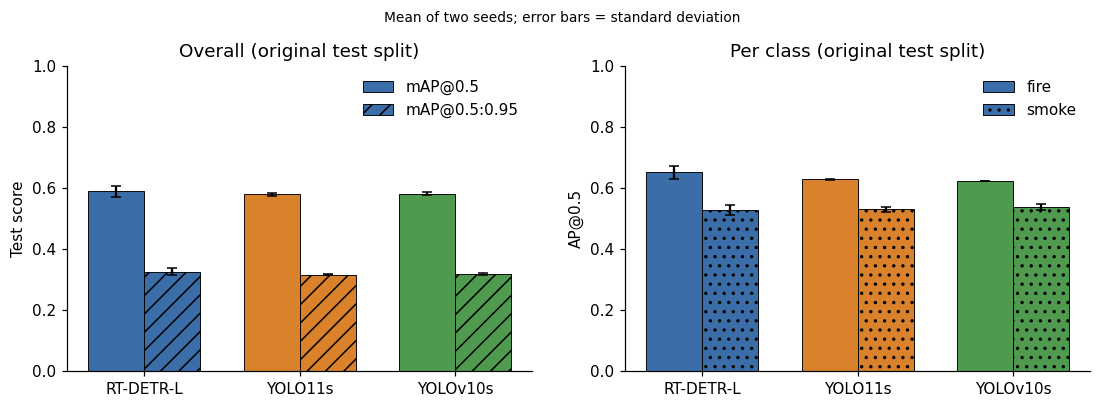


=== cleaned dataset: overall test results (mean ± std over seeds) ===
           seeds      precision         recall          mAP50       mAP50_95
RT-DETR-L      2  0.583 ± 0.007  0.461 ± 0.001  0.501 ± 0.005  0.225 ± 0.004
YOLO11s        2  0.540 ± 0.012  0.446 ± 0.000  0.470 ± 0.005  0.212 ± 0.003
YOLOv10s       2  0.543 ± 0.009  0.450 ± 0.013  0.474 ± 0.004  0.214 ± 0.001

=== cleaned dataset: per class ===
               fire_AP50   fire_AP50_95     smoke_AP50  smoke_AP50_95
RT-DETR-L  0.551 ± 0.005  0.243 ± 0.000  0.450 ± 0.004  0.207 ± 0.008
YOLO11s    0.518 ± 0.001  0.232 ± 0.002  0.423 ± 0.009  0.192 ± 0.005
YOLOv10s   0.520 ± 0.003  0.236 ± 0.001  0.428 ± 0.004  0.193 ± 0.001

=== cleaned dataset: fire–smoke AP difference (positive = higher fire AP) ===
          AP50 fire - smoke AP50-95 fire - smoke
RT-DETR-L     0.101 ± 0.001        0.036 ± 0.008
YOLO11s       0.094 ± 0.007        0.040 ± 0.003
YOLOv10s      0.092 ± 0.001        0.043 ± 0.000


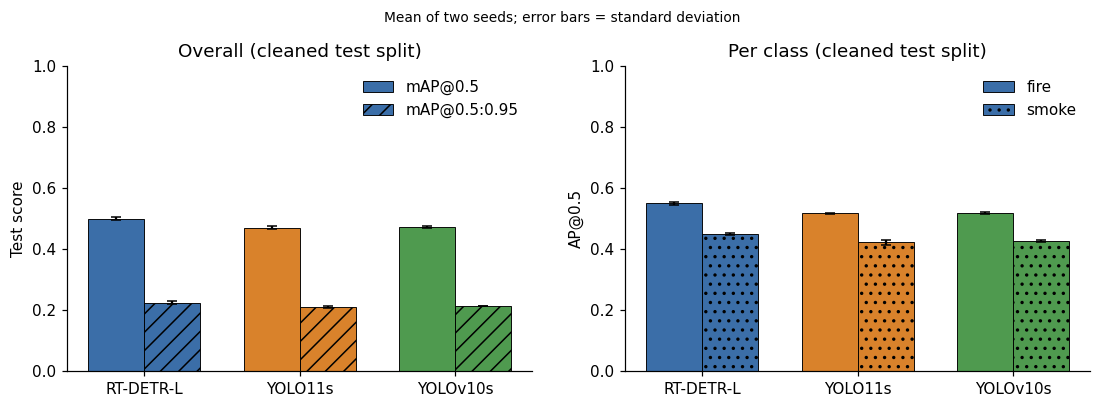

In [4]:
METRICS = ["precision", "recall", "mAP50", "mAP50_95"]
CLASS_METRICS = [f"{c}_{k}" for c in CLASS_NAMES for k in ("precision", "recall", "AP50", "AP50_95") if f"{c}_{k}" in runs.columns]

COMPARISON = {}
for ds in DATASETS:
    d = runs[runs.dataset == ds]
    if d.empty: continue
    models = model_sort(d.model)
    t = pd.DataFrame({c: [pm(d[d.model == m][c]) for m in models] for c in METRICS + CLASS_METRICS}, index=models)
    t.insert(0, "seeds", [int((d.model == m).sum()) for m in models])
    gap = pd.DataFrame({"AP50 fire - smoke": [pm(d[d.model == m].fire_AP50 - d[d.model == m].smoke_AP50) for m in models],
                        "AP50-95 fire - smoke": [pm(d[d.model == m].fire_AP50_95 - d[d.model == m].smoke_AP50_95) for m in models]}, index=models)
    COMPARISON[ds] = t
    save_table(t, f"table_comparison_{ds}"); save_table(gap, f"table_fire_smoke_gap_{ds}")
    d.groupby("model")[METRICS + CLASS_METRICS].agg(["mean", "std"]).round(4).to_csv(TAB / f"table_comparison_{ds}_numeric.csv")
    print(f"\n=== {ds} dataset: overall test results (mean ± std over seeds) ===\n" + t[["seeds"] + METRICS].to_string())
    print(f"\n=== {ds} dataset: per class ===\n" + t[[c for c in CLASS_METRICS if "AP" in c]].to_string())
    print(f"\n=== {ds} dataset: fire–smoke AP difference (positive = higher fire AP) ===\n" + gap.to_string())

    x = np.arange(len(models)); w = 0.36
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
    for k, (col, lab, hatch) in enumerate([("mAP50", "mAP@0.5", ""), ("mAP50_95", "mAP@0.5:0.95", "//")]):
        mu = [d[d.model == m][col].mean() for m in models]; sd = [d[d.model == m][col].std() for m in models]
        axes[0].bar(x + (k - 0.5) * w, mu, w, yerr=np.nan_to_num(sd), capsize=3, label=lab, hatch=hatch,
                    color=[COLORS.get(m, "#888") for m in models], edgecolor="black", linewidth=0.6)
    axes[0].set_xticks(x, models); axes[0].set_ylabel("Test score"); axes[0].set_ylim(0, 1); axes[0].legend(frameon=False)
    axes[0].set_title(f"Overall ({ds} test split)")
    for k, (cn, hatch) in enumerate([("fire", ""), ("smoke", "..")]):
        mu = [d[d.model == m][f"{cn}_AP50"].mean() for m in models]; sd = [d[d.model == m][f"{cn}_AP50"].std() for m in models]
        axes[1].bar(x + (k - 0.5) * w, mu, w, yerr=np.nan_to_num(sd), capsize=3, label=cn, hatch=hatch,
                    color=[COLORS.get(m, "#888") for m in models], edgecolor="black", linewidth=0.6)
    axes[1].set_xticks(x, models); axes[1].set_ylabel("AP@0.5"); axes[1].set_ylim(0, 1); axes[1].legend(frameon=False)
    axes[1].set_title(f"Per class ({ds} test split)")
    fig.suptitle("Mean of two seeds; error bars = standard deviation", y=1.02, fontsize=9)
    savefig(fig, f"comparison_{ds}")

#### 3. Training curves and convergence

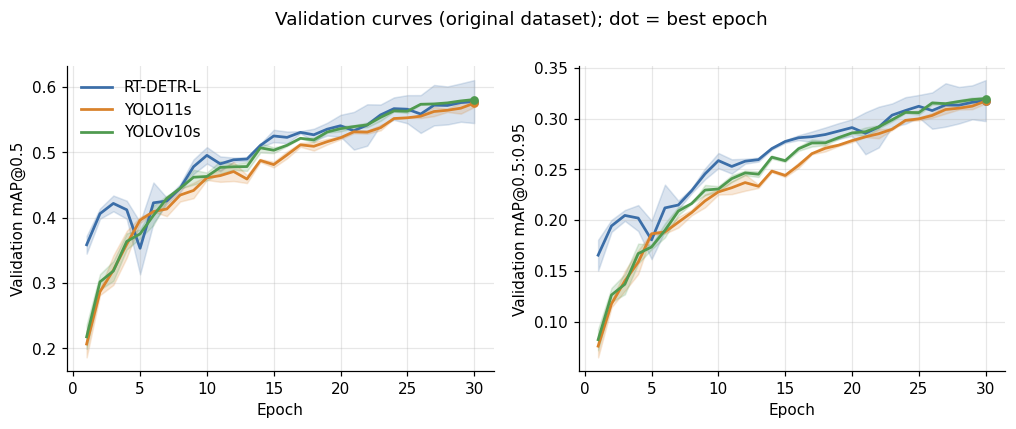

/tmp/ipykernel_865/3207348118.py:9: RuntimeWarning: Mean of empty slice
  return np.arange(1, L + 1), np.nanmean(Y, 0), np.nanmin(Y, 0), np.nanmax(Y, 0)
/tmp/ipykernel_865/3207348118.py:9: RuntimeWarning: All-NaN slice encountered
  return np.arange(1, L + 1), np.nanmean(Y, 0), np.nanmin(Y, 0), np.nanmax(Y, 0)


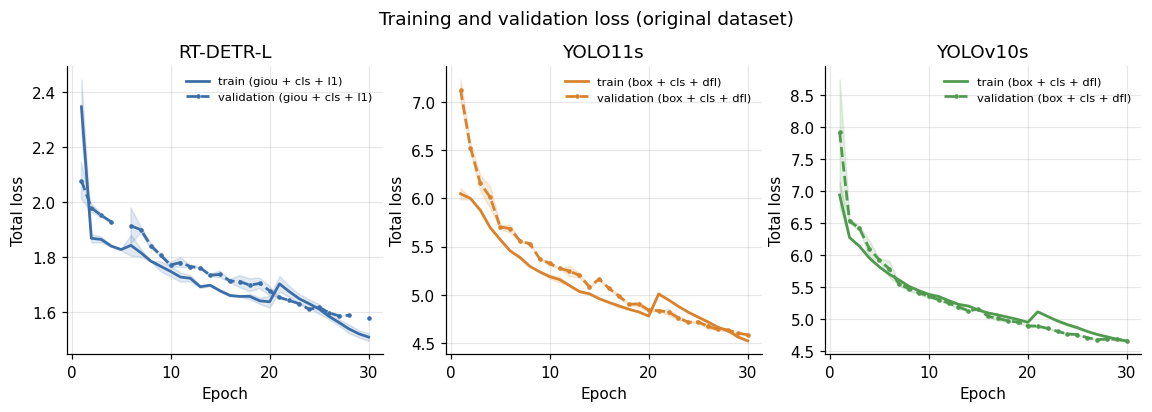

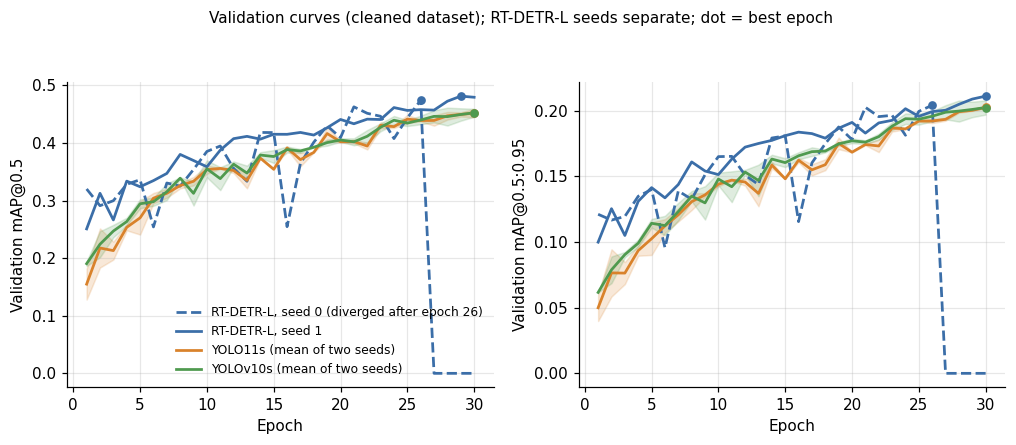

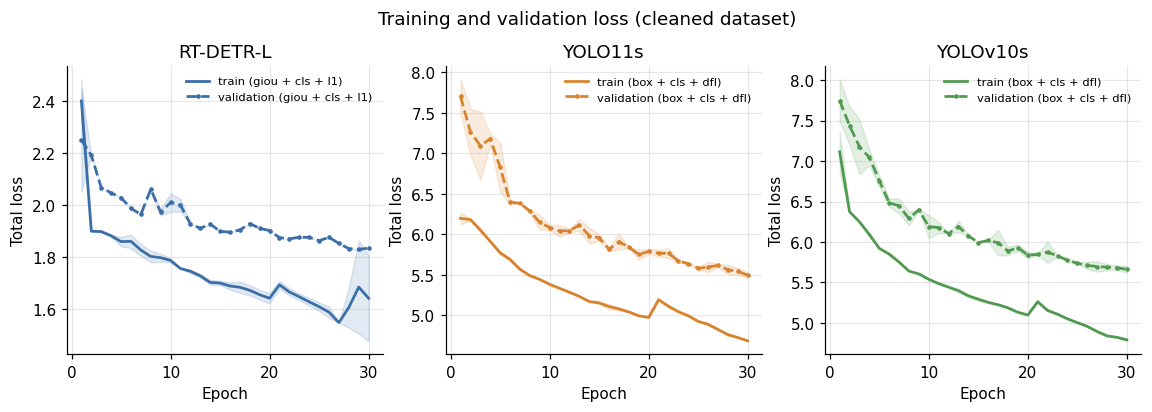

Convergence at the 30-epoch budget (validation mAP@0.5:0.95)
 dataset     model  seed  epochs  best epoch (val mAP50-95)  best epoch (Ultralytics)  val mAP50-95 at epoch 25  val mAP50-95 at last epoch  gain over last 5 epochs still improving
 cleaned RT-DETR-L     0      30                         26                        26                    0.1994                      0.0000                  -0.1994              no
 cleaned RT-DETR-L     1      30                         30                        30                    0.1956                      0.2110                   0.0154             yes
 cleaned   YOLO11s     0      30                         30                        30                    0.1926                      0.2034                   0.0108             yes
 cleaned   YOLO11s     1      30                         30                        30                    0.1916                      0.2015                   0.0099             yes
 cleaned  YOLOv10s     0      30  

In [5]:
def col(df, name):
    return df[name].astype(float).values if name in df.columns else None

def seed_band(ds, model, getter):
    ys = [getter(CURVES[k]) for k in CURVES if k[0] == ds and k[1] == model]
    ys = [y for y in ys if y is not None]
    if not ys: return None
    L = min(len(y) for y in ys); Y = np.vstack([y[:L] for y in ys])
    return np.arange(1, L + 1), np.nanmean(Y, 0), np.nanmin(Y, 0), np.nanmax(Y, 0)

CONV = []
for ds in DATASETS:
    models = [m for m in MODEL_ORDER if any(k[0] == ds and k[1] == m for k in CURVES)]
    if not models: continue
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
    for ax, (key, lab) in zip(axes, [("metrics/mAP50(B)", "Validation mAP@0.5"), ("metrics/mAP50-95(B)", "Validation mAP@0.5:0.95")]):
        for m in models:
            if ds == "cleaned" and m == "RT-DETR-L":
                for k_ in sorted(k_ for k_ in CURVES if k_[0] == ds and k_[1] == m):
                    y = col(CURVES[k_], key)
                    if y is None: continue
                    e = np.arange(1, len(y) + 1); seed = k_[2]
                    lab_s = f"{m}, seed {seed}" + (" (diverged after epoch 26)" if np.nanmin(y[-3:]) < 0.01 else "")
                    ax.plot(e, y, "--" if seed == min(k[2] for k in CURVES if k[0] == ds and k[1] == m) else "-",
                            color=COLORS.get(m), label=lab_s, lw=1.8)
                    be = int(np.nanargmax(y)) + 1; ax.scatter([be], [y[be - 1]], color=COLORS.get(m), s=22, zorder=3)
                continue
            b = seed_band(ds, m, lambda d, k=key: col(d, k))
            if b is None: continue
            e, mu, lo, hi = b
            ax.plot(e, mu, color=COLORS.get(m), label=f"{m} (mean of two seeds)" if ds == "cleaned" else m, lw=1.8)
            ax.fill_between(e, lo, hi, color=COLORS.get(m), alpha=0.18)
            be = int(np.argmax(mu)) + 1; ax.scatter([be], [mu[be - 1]], color=COLORS.get(m), s=22, zorder=3)
        ax.set_xlabel("Epoch"); ax.set_ylabel(lab); ax.grid(alpha=0.3)
    if ds == "cleaned":
        axes[0].legend(frameon=False, fontsize=8, loc="lower right")
        fig.suptitle("Validation curves (cleaned dataset); RT-DETR-L seeds separate; dot = best epoch", y=1.06, fontsize=10)
    else:
        axes[0].legend(frameon=False); fig.suptitle(f"Validation curves ({ds} dataset); dot = best epoch", y=1.02)
    savefig(fig, f"curves_val_map_{ds}")

    fig, axes = plt.subplots(1, len(models), figsize=(4.2 * len(models), 3.4), squeeze=False)
    for ax, m in zip(axes[0], models):
        any_df = next(CURVES[k] for k in CURVES if k[0] == ds and k[1] == m)
        tl = [c for c in any_df.columns if c.startswith("train/") and c.endswith("loss")]
        vl = [c for c in any_df.columns if c.startswith("val/") and c.endswith("loss")]
        for cols_, ls, lab in [(tl, "-", "train"), (vl, "--", "validation")]:
            if not cols_: continue
            b = seed_band(ds, m, lambda d, c=cols_: d[c].astype(float).sum(axis=1, skipna=False).values)
            e, mu, lo, hi = b
            ok = np.isfinite(mu)
            ax.plot(e, np.where(ok, mu, np.nan), ls, color=COLORS.get(m), lw=1.8, marker="." if lab == "validation" else None, ms=4,
                    label=f"{lab} ({' + '.join(c.split('/')[1].replace('_loss', '') for c in cols_)})")
            ax.fill_between(e, np.where(ok, lo, np.nan), np.where(ok, hi, np.nan), color=COLORS.get(m), alpha=0.15)
        ax.set_title(m); ax.set_xlabel("Epoch"); ax.set_ylabel("Total loss"); ax.grid(alpha=0.3); ax.legend(frameon=False, fontsize=7.5)
    fig.suptitle(f"Training and validation loss ({ds} dataset)", y=1.03)
    savefig(fig, f"curves_loss_{ds}")

    for (d_, m, seed), df in CURVES.items():
        if d_ != ds: continue
        y = col(df, "metrics/mAP50-95(B)")
        if y is None or len(y) < 6: continue
        gain = float(y[-1] - y[-6])
        CONV.append({"dataset": ds, "model": m, "seed": seed, "epochs": len(y),
                     "best epoch (val mAP50-95)": int(np.nanargmax(y)) + 1,
                     "best epoch (Ultralytics)": (REPORTS[(d_, m, seed)].get("validation") or {}).get("best_epoch", {}).get("epoch"),
                     "val mAP50-95 at epoch 25": round(float(y[-6]), 4), "val mAP50-95 at last epoch": round(float(y[-1]), 4),
                     "gain over last 5 epochs": round(gain, 4), "still improving": "yes" if gain > 0.005 else "no"})
conv = pd.DataFrame(CONV)
if len(conv):
    conv["r"] = conv.model.map({m: i for i, m in enumerate(MODEL_ORDER)}); conv = conv.sort_values(["dataset", "r", "seed"]).drop(columns="r")
    save_table(conv, "table_convergence", index=False)
    print("Convergence at the 30-epoch budget (validation mAP@0.5:0.95)"); print(conv.to_string(index=False))
    s = conv.groupby("model")["gain over last 5 epochs"].agg(["min", "max"])
    print("\nEpoch convergence summary:")
    for m in model_sort(conv.model):
        c = conv[conv.model == m]
        print(f"  {m}: best epoch {sorted(set(c['best epoch (val mAP50-95)']))}, gain over the last five epochs "
              f"{s.at[m, 'min']:+.3f} to {s.at[m, 'max']:+.3f}")
    if (conv["still improving"] == "yes").any():
        print("  -> at least one run was still improving at epoch 30: report this as a limitation of the fixed budget.")

#### 4. Model size and inference time (training reports)
Time per image from each run's test evaluation (T4, batch 8). FPS uses the total time, which includes NMS for YOLO11s.


=== original ===
           parameters (M)  best.pt (MB)     pre (ms) inference (ms)    post (ms) total (ms/img)  FPS (total)       mAP50-95
RT-DETR-L           32.81          63.2  1.25 ± 0.23   40.19 ± 4.24  0.21 ± 0.05   41.65 ± 3.96         24.0  0.327 ± 0.010
YOLO11s              9.43          18.3  1.48 ± 0.15    9.77 ± 0.47  1.39 ± 0.25   12.62 ± 0.87         79.2  0.317 ± 0.002
YOLOv10s             8.07          15.8  1.31 ± 0.04    9.52 ± 0.78  1.54 ± 0.32   12.37 ± 0.42         80.9  0.320 ± 0.004


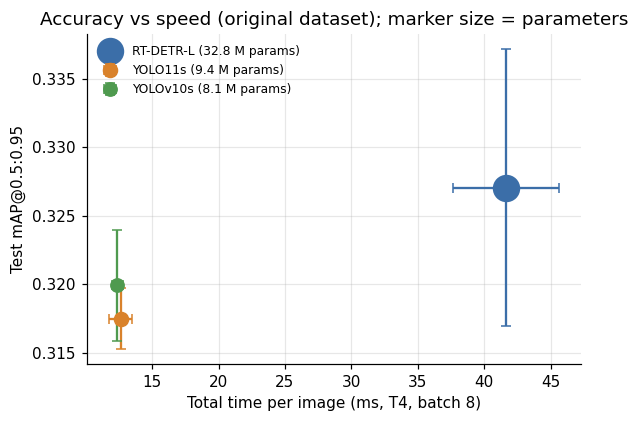


=== cleaned ===
           parameters (M)  best.pt (MB)     pre (ms) inference (ms)    post (ms) total (ms/img)  FPS (total)       mAP50-95
RT-DETR-L           32.81          63.2  1.27 ± 0.03   42.92 ± 2.09  0.17 ± 0.01   44.37 ± 2.12         22.5  0.225 ± 0.004
YOLO11s              9.43          18.3  1.48 ± 0.15    9.44 ± 0.11  1.58 ± 0.01   12.49 ± 0.03         80.1  0.212 ± 0.003
YOLOv10s             8.07          15.8  1.52 ± 0.23   10.04 ± 0.51  1.33 ± 0.07   12.89 ± 0.66         77.6  0.214 ± 0.001


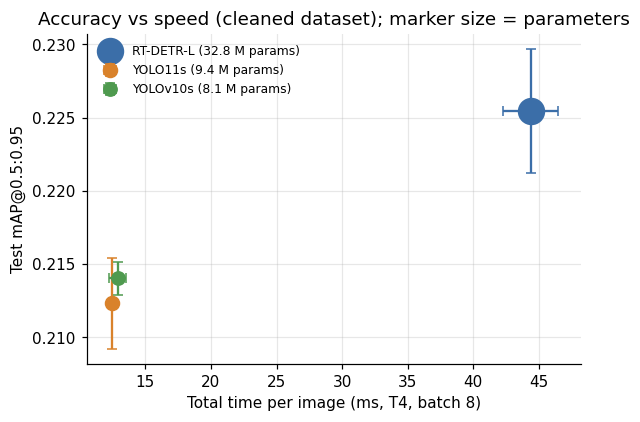

In [6]:
SIZE_SPEED = {}
for ds in DATASETS:
    d = runs[runs.dataset == ds]
    if d.empty: continue
    models = model_sort(d.model)
    t = pd.DataFrame({
        "parameters (M)": [d[d.model == m].params_M.mean() for m in models],
        "best.pt (MB)":   [d[d.model == m].size_MB.mean() for m in models],
        "pre (ms)":       [pm(d[d.model == m].pre_ms, 2) for m in models],
        "inference (ms)": [pm(d[d.model == m].inference_ms, 2) for m in models],
        "post (ms)":      [pm(d[d.model == m].post_ms, 2) for m in models],
        "total (ms/img)": [pm(d[d.model == m].total_ms, 2) for m in models],
        "FPS (total)":    [round(1000 / d[d.model == m].total_ms.mean(), 1) for m in models],
        "mAP50-95":       [pm(d[d.model == m].mAP50_95) for m in models]}, index=models)
    SIZE_SPEED[ds] = t; save_table(t, f"table_size_speed_reports_{ds}")
    print(f"\n=== {ds} ===\n" + t.to_string())

    fig, ax = plt.subplots(figsize=(5.8, 3.9))
    for m in models:
        g = d[d.model == m]
        if g.total_ms.isna().all(): continue
        ax.errorbar(g.total_ms.mean(), g.mAP50_95.mean(), xerr=g.total_ms.std() if len(g) > 1 else None,
                    yerr=g.mAP50_95.std() if len(g) > 1 else None, fmt="o", ms=6 + g.params_M.mean() / 3,
                    color=COLORS.get(m), capsize=3, label=f"{m} ({g.params_M.mean():.1f} M params)")
    ax.set_xlabel("Total time per image (ms, T4, batch 8)"); ax.set_ylabel("Test mAP@0.5:0.95"); ax.grid(alpha=0.3)
    ax.legend(frameon=False, fontsize=8); ax.set_title(f"Accuracy vs speed ({ds} dataset); marker size = parameters")
    savefig(fig, f"accuracy_vs_speed_{ds}")

#### 5. Original vs cleaned dataset

           precision original  precision cleaned  precision change  recall original  recall cleaned  recall change  mAP50 original  mAP50 cleaned  mAP50 change  mAP50_95 original  mAP50_95 cleaned  mAP50_95 change  fire_AP50 original  fire_AP50 cleaned  fire_AP50 change  smoke_AP50 original  smoke_AP50 cleaned  smoke_AP50 change  fire_AP50_95 original  fire_AP50_95 cleaned  fire_AP50_95 change  smoke_AP50_95 original  smoke_AP50_95 cleaned  smoke_AP50_95 change
model                                                                                                                                                                                                                                                                                                                                                                                                                                                                            
RT-DETR-L              0.6581             0.5831           -0.0750  

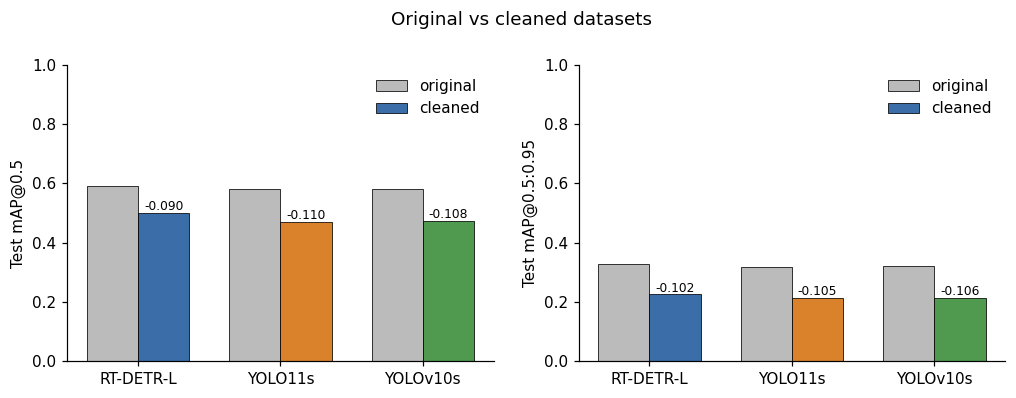

In [7]:
if {"original", "cleaned"} <= set(runs.dataset):
    rows = []
    for m in model_sort(runs.model):
        r = {"model": m}
        for c in METRICS + ["fire_AP50", "smoke_AP50", "fire_AP50_95", "smoke_AP50_95"]:
            o = runs[(runs.dataset == "original") & (runs.model == m)][c].mean()
            k = runs[(runs.dataset == "cleaned") & (runs.model == m)][c].mean()
            r[f"{c} original"], r[f"{c} cleaned"], r[f"{c} change"] = round(o, 4), round(k, 4), round(k - o, 4)
        rows.append(r)
    dd = pd.DataFrame(rows).set_index("model").dropna(subset=["mAP50_95 change"])
    save_table(dd, "table_original_vs_cleaned"); print(dd.to_string())

    models = list(dd.index); x = np.arange(len(models)); w = 0.36
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
    for ax, c, lab in [(axes[0], "mAP50", "mAP@0.5"), (axes[1], "mAP50_95", "mAP@0.5:0.95")]:
        ax.bar(x - w / 2, dd[f"{c} original"], w, label="original", color="#bbbbbb", edgecolor="black", linewidth=0.5)
        ax.bar(x + w / 2, dd[f"{c} cleaned"], w, label="cleaned", color=[COLORS.get(m) for m in models], edgecolor="black", linewidth=0.5)
        for i, m in enumerate(models):
            ax.text(x[i] + w / 2, dd.at[m, f"{c} cleaned"] + 0.01, f"{dd.at[m, f'{c} change']:+.3f}", ha="center", fontsize=8)
        ax.set_xticks(x, models); ax.set_ylabel(f"Test {lab}"); ax.set_ylim(0, 1); ax.legend(frameon=False)
    fig.suptitle("Original vs cleaned datasets", y=1.02)
    savefig(fig, "original_vs_cleaned")
else:
    print("Skipped: runs of both datasets are needed.")

#### 6. Benchmark against Živanović et al. [Y]
We use the same dataset and the reported test split of 1,107 images. Accuracy results are compared with Živanović et al. [Y], while inference speed is not directly comparable because their experiments used an RTX 4090 and ours used a Tesla T4.

              source                        model mAP50 (mean ± std) mAP50-95 (mean ± std)  fire AP50-95  smoke AP50-95  time (ms/img)          hardware
           This work                    RT-DETR-L      0.591 ± 0.019         0.327 ± 0.010        0.3556         0.2985         41.650       T4, batch 8
           This work                      YOLO11s      0.580 ± 0.005         0.317 ± 0.002        0.3431         0.2919         12.625       T4, batch 8
           This work                     YOLOv10s      0.582 ± 0.005         0.320 ± 0.004        0.3428         0.2970         12.365       T4, batch 8
Živanović et al. [Y] Faster R-CNN (ResNet-50-FPN)              0.238                 0.088        0.1253         0.0516         12.140 RTX 4090, batch 1
Živanović et al. [Y]    RetinaNet (ResNet-50-FPN)              0.362                 0.126        0.1411         0.1113         11.130 RTX 4090, batch 1
Živanović et al. [Y]   Faster R-CNN (MobileNetV2)              0.369              

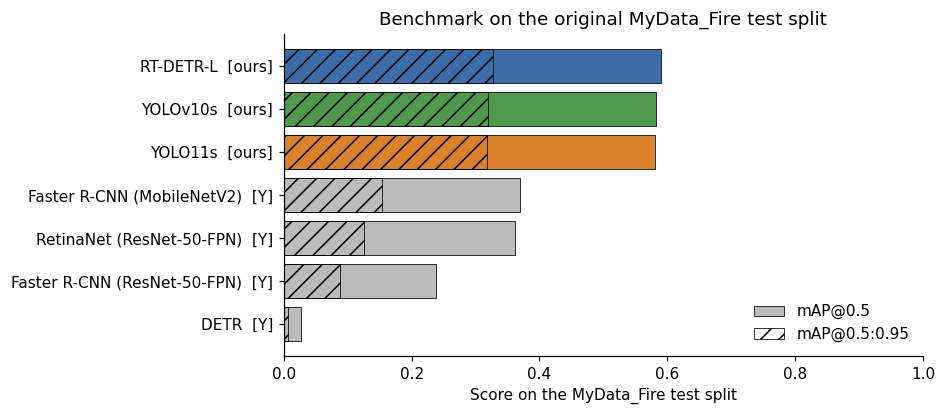

In [8]:
ours = runs[runs.dataset == "original"]
if ours.empty:
    print("Skipped: no original-dataset runs.")
else:
    rows = []
    for m in model_sort(ours.model):
        g = ours[ours.model == m]
        rows.append({"source": "This work", "model": m, "mAP50": g.mAP50.mean(), "mAP50_95": g.mAP50_95.mean(),
                     "fire AP50-95": g.fire_AP50_95.mean(), "smoke AP50-95": g.smoke_AP50_95.mean(),
                     "mAP50 (mean ± std)": pm(g.mAP50), "mAP50-95 (mean ± std)": pm(g.mAP50_95),
                     "time (ms/img)": g.total_ms.mean(), "hardware": "T4, batch 8"})
    for m, v in SYMMETRY.items():
        rows.append({"source": "Živanović et al. [Y]", "model": m, "mAP50": v["mAP50"], "mAP50_95": v["mAP50_95"],
                     "fire AP50-95": v["fire_AP50_95"], "smoke AP50-95": v["smoke_AP50_95"],
                     "mAP50 (mean ± std)": f"{v['mAP50']:.3f}", "mAP50-95 (mean ± std)": f"{v['mAP50_95']:.3f}",
                     "time (ms/img)": v["latency_ms"], "hardware": "RTX 4090, batch 1"})
    bench = pd.DataFrame(rows)
    save_table(bench.round(4), "table_benchmark_symmetry", index=False)
    print(bench[["source", "model", "mAP50 (mean ± std)", "mAP50-95 (mean ± std)", "fire AP50-95", "smoke AP50-95", "time (ms/img)", "hardware"]]
          .round(4).to_string(index=False))
    best_theirs = max(SYMMETRY.items(), key=lambda kv: kv[1]["mAP50_95"])
    best_ours = bench[bench.source == "This work"].sort_values("mAP50_95", ascending=False).iloc[0]
    print(f"\nBest in [Y] on MyData_Fire: {best_theirs[0]} (mAP50-95 {best_theirs[1]['mAP50_95']:.3f}, mAP50 {best_theirs[1]['mAP50']:.3f}). "
          f"Best here: {best_ours.model} (mAP50-95 {best_ours.mAP50_95:.3f}, mAP50 {best_ours.mAP50:.3f}).")

    b = bench.sort_values("mAP50")
    fig, ax = plt.subplots(figsize=(7.5, 3.8))
    ax.barh(b.model + "  [" + np.where(b.source == "This work", "ours", "Y") + "]", b.mAP50,
            color=[COLORS.get(m, "#bbbbbb") for m in b.model], edgecolor="black", linewidth=0.5, label="mAP@0.5")
    ax.barh(b.model + "  [" + np.where(b.source == "This work", "ours", "Y") + "]", b.mAP50_95, color="none",
            edgecolor="black", hatch="//", linewidth=0.5, label="mAP@0.5:0.95")
    ax.set_xlabel("Score on the MyData_Fire test split"); ax.set_xlim(0, 1); ax.legend(frameon=False, loc="lower right")
    ax.set_title("Benchmark on the original MyData_Fire test split")
    savefig(fig, "benchmark_symmetry")

#### 7. Category labels

In [9]:
IN = Path(INPUT_DIR)
CAT_FINAL = None

def read_annot(p):
    df = pd.read_excel(p, dtype=object)
    df.columns = [re.sub(r"\s+", " ", str(c)).strip() for c in df.columns]
    missing = {"Image ID", *CATEGORIES} - set(df.columns)
    if missing:
        raise ValueError(f"{p.name}: missing columns {missing}")
    df["Image ID"] = df["Image ID"].astype(str).str.strip()
    df = df.drop_duplicates("Image ID").set_index("Image ID")[CATEGORIES]
    return df.apply(pd.to_numeric, errors="coerce").astype("Int64")

pa, pb, padj = IN / ANNOTATOR_FILES[0], IN / ANNOTATOR_FILES[1], IN / ADJUDICATED_FILE

if pa.exists() and pb.exists() and padj.exists():
    A, B = read_annot(pa), read_annot(pb)
    common = A.index.intersection(B.index)

    if len(common) != len(A) or len(common) != len(B):
        print("WARNING: the two annotator files do not list the same images")

    dis = {(i, c) for i in common for c in CATEGORIES if A.at[i, c] != B.at[i, c]}

    adj = pd.read_excel(padj, dtype=object)
    adj.columns = [re.sub(r"\s+", " ", str(c)).strip() for c in adj.columns]
    adj["Image ID"] = adj["Image ID"].astype(str).str.strip()
    adj["category"] = adj["category"].astype(str).str.strip()

    adj_keys = set(zip(adj["Image ID"], adj["category"]))
    FINAL = A.loc[common].copy()

    for _, r in adj.iterrows():
        if (r["Image ID"], r["category"]) in dis:
            FINAL.at[r["Image ID"], r["category"]] = int(r["FINAL"])

    unresolved = dis - adj_keys
    if unresolved:
        raise ValueError(
            f"{len(unresolved)} annotation disagreements remain unresolved in {ADJUDICATED_FILE}."
        )

    CAT_FINAL = FINAL.astype(int)
    CAT_FINAL.to_csv(OUT / "categories_final.csv")

    print(f"Reviewed images: {len(CAT_FINAL)} | disagreements resolved: {len(dis & adj_keys)} of {len(dis)}")
    print("Final category sizes:", {c: int(CAT_FINAL[c].sum()) for c in CATEGORIES})

else:
    print(f"Annotation analysis skipped: required input files are missing from {IN}.")

Reviewed images: 173 | disagreements resolved: 155 of 155
Final category sizes: {'Weak / Diffuse Smoke': 89, 'Complex Background': 79, 'Poor Illumination': 42}


#### 8. Test images and condition groups


In [10]:
GPU_READY = False
try:
    import torch
    HAS_GPU = torch.cuda.is_available()
except Exception:
    torch, HAS_GPU = None, False

if not HAS_GPU:
    print("WARNING: GPU acceleration is unavailable. Subsequent inference and evaluation may be slow.")


def md5_of(p, chunk=1 << 20):
    h = hashlib.md5()
    with open(p, "rb") as f:
        for b in iter(lambda: f.read(chunk), b""):
            h.update(b)
    return h.hexdigest()


def find_test_dirs(root):
    for p in sorted(Path(root).rglob("images")):
        if p.is_dir() and p.parent.name.lower() == "test" and (p.parent / "labels").is_dir():
            return p, p.parent / "labels"
    return None, None


TEST_IMG, TEST_LBL = (
    find_test_dirs(CLEAN_EXTRACT_DIR)
    if Path(CLEAN_EXTRACT_DIR).exists()
    else (None, None)
)

if TEST_IMG is None:
    zp = Path(CLEAN_ZIP_PATH)

    if not (zp.exists() and zp.stat().st_size == CLEAN_BYTES):
        found = None

        if IN_COLAB:
            for cur, dirs, files in os.walk("/content/drive/MyDrive"):
                dirs[:] = [
                    d for d in dirs
                    if not d.startswith(".")
                    and d not in ("all_runs", "all_runs_clean", Path(OUT_DIR).name)
                ]

                for f in files:
                    if (
                        CLEAN_ZIP_HINT in f
                        and f.endswith(".zip")
                        and (Path(cur) / f).stat().st_size == CLEAN_BYTES
                    ):
                        found = Path(cur) / f
                        break

                if found:
                    break

        if found:
            print("Copying the cleaned dataset from Drive:", found)
            shutil.copy(found, zp)
        else:
            subprocess.run(
                [sys.executable, "-m", "pip", "install", "-q", "gdown"],
                check=False
            )
            import gdown
            gdown.download(
                CLEAN_DATASET_LINK,
                str(zp),
                fuzzy=True,
                quiet=False
            )

    got = md5_of(zp)

    if got != CLEAN_MD5:
        raise RuntimeError(
            f"MD5 of {zp} is {got}, expected {CLEAN_MD5}: wrong or incomplete file"
        )

    with zipfile.ZipFile(zp) as z:
        z.extractall(
            CLEAN_EXTRACT_DIR,
            members=[
                n for n in z.namelist()
                if re.search(r"(^|/)test/(images|labels)/", n)
            ]
        )

    TEST_IMG, TEST_LBL = find_test_dirs(CLEAN_EXTRACT_DIR)

assert TEST_IMG is not None, (
    "test/images and test/labels not found in the cleaned dataset"
)


from PIL import Image

IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

TEST_IMAGES = sorted(
    p.name for p in TEST_IMG.iterdir()
    if p.suffix.lower() in IMG_EXT
)

print(
    f"Cleaned test images: {len(TEST_IMAGES)} "
    f"(expected {EXPECTED['test_images']['cleaned']})"
)


def read_labels(lbl_path):
    """Read YOLO labels as [class, cx, cy, width, height]; convert polygons to bounding boxes."""
    out = []

    if lbl_path.exists():
        for line in lbl_path.read_text().splitlines():
            v = line.split()

            if len(v) < 5:
                continue

            c = int(float(v[0]))
            nums = np.array(v[1:], dtype=float)

            if len(nums) == 4:
                out.append([c, *nums])
            else:
                xs, ys = nums[0::2], nums[1::2]
                out.append([
                    c,
                    (xs.min() + xs.max()) / 2,
                    (ys.min() + ys.max()) / 2,
                    xs.max() - xs.min(),
                    ys.max() - ys.min()
                ])

    return np.array(out, dtype=float).reshape(-1, 5)


GT, IMG_SIZE = {}, {}

for im in TEST_IMAGES:
    GT[im] = read_labels(TEST_LBL / (Path(im).stem + ".txt"))

    with Image.open(TEST_IMG / im) as I:
        IMG_SIZE[im] = I.size


def small_mask(im):
    g, (W, H) = GT[im], IMG_SIZE[im]
    return (g[:, 3] * W) * (g[:, 4] * H) < COCO_SMALL_PX2


SMALL_IMAGES = [
    im for im in TEST_IMAGES
    if small_mask(im).any()
]

n_small_fire = sum(
    int((small_mask(im) & (GT[im][:, 0] == 0)).sum())
    for im in TEST_IMAGES
)

n_small_smoke = sum(
    int((small_mask(im) & (GT[im][:, 0] == 1)).sum())
    for im in TEST_IMAGES
)

print(
    f"Small targets (COCO): {len(SMALL_IMAGES)} images, "
    f"{n_small_fire} small fire boxes, "
    f"{n_small_smoke} small smoke boxes "
    f"(expected: {EXPECTED_SMALL['images']}, "
    f"{EXPECTED_SMALL['fire_boxes']}, "
    f"{EXPECTED_SMALL['smoke_boxes']})"
)

if (
    len(SMALL_IMAGES),
    n_small_fire,
    n_small_smoke
) != tuple(EXPECTED_SMALL.values()):
    print(
        "WARNING: Small-target counts differ from the expected values. "
        "Verify the dataset version."
    )


GROUPS = {
    "Full cleaned test": list(TEST_IMAGES)
}

if CAT_FINAL is not None:
    missing = sorted(set(CAT_FINAL.index) - set(TEST_IMAGES))

    if missing:
        print(
            f"WARNING: {len(missing)} categorized images are not in "
            f"the cleaned test split, e.g. {missing[:3]}"
        )

    cat_ok = CAT_FINAL.loc[
        CAT_FINAL.index.intersection(TEST_IMAGES)
    ]

    sample = sorted(
        set(cat_ok.index) | set(SMALL_IMAGES)
    )

    GROUPS["Challenging sample (all)"] = sample

    print(
        f"Challenging-condition sample: {len(sample)} images "
        f"(expected {EXPECTED_SAMPLE})"
    )

    for c in CATEGORIES:
        GROUPS[c] = sorted(
            cat_ok.index[cat_ok[c] == 1]
        )

else:
    print(
        "Manual categories are unavailable. "
        "Only the full test split and small-target images will be evaluated."
    )

GROUPS["Small Targets (COCO)"] = SMALL_IMAGES


def origin(im):
    p = im.split("__", 1)[0].lower()
    return p if p in ("train", "valid", "test") else "unknown"


grp = []

for g, ims in GROUPS.items():
    boxes = (
        np.concatenate([GT[i] for i in ims])
        if ims
        else np.zeros((0, 5))
    )

    o = pd.Series(
        [origin(i) for i in ims]
    ).value_counts()

    sm = (
        np.concatenate([small_mask(i) for i in ims])
        if ims
        else np.zeros(0, bool)
    )

    grp.append({
        "group": g,
        "images": len(ims),
        "fire boxes": int((boxes[:, 0] == 0).sum()),
        "smoke boxes": int((boxes[:, 0] == 1).sum()),
        "small fire boxes": int(
            ((boxes[:, 0] == 0) & sm).sum()
        ),
        "small smoke boxes": int(
            ((boxes[:, 0] == 1) & sm).sum()
        ),
        "seen in original training (train__)": (
            f"{o.get('train', 0)} "
            f"({100 * o.get('train', 0) / max(len(ims), 1):.0f}%)"
        ),
        "used for original validation (valid__)": (
            f"{o.get('valid', 0)} "
            f"({100 * o.get('valid', 0) / max(len(ims), 1):.0f}%)"
        ),
        "note": (
            "few images"
            if g != "Full cleaned test" and len(ims) < MIN_IMAGES
            else ""
        )
    })

GROUP_INFO = pd.DataFrame(grp).set_index("group")

save_table(GROUP_INFO, "table_condition_groups")
print("\n" + GROUP_INFO.to_string())


SUB = Path("/content/condition_subsets")

shutil.rmtree(SUB, ignore_errors=True)

YAMLS = {}

for g, ims in GROUPS.items():
    if not ims:
        continue

    sl = re.sub(
        r"[^a-z0-9]+", "_", g.lower()
    ).strip("_")

    (SUB / sl / "images").mkdir(parents=True)
    (SUB / sl / "labels").mkdir()

    for f in ims:
        os.symlink(
            TEST_IMG / f,
            SUB / sl / "images" / f
        )

        lf = TEST_LBL / (Path(f).stem + ".txt")

        if lf.exists():
            os.symlink(
                lf,
                SUB / sl / "labels" / lf.name
            )

    y = SUB / f"{sl}.yaml"

    y.write_text(
        f"path: {SUB / sl}\n"
        "train: images\n"
        "val: images\n"
        "names:\n"
        "  0: fire\n"
        "  1: smoke\n"
    )

    YAMLS[g] = y


try:
    import ultralytics

    if ultralytics.__version__ != EXPECTED["ultralytics"]:
        raise ImportError

except ImportError:
    r = subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            ULTRALYTICS_SPEC
        ],
        capture_output=True,
        text=True
    )

    if r.returncode != 0:
        print(r.stderr[-1500:])


try:
    from ultralytics import YOLO, RTDETR
    GPU_READY = HAS_GPU

except Exception as e:
    print("Ultralytics not available:", e)


DEVICE = 0 if HAS_GPU else "cpu"


def load_model(key):
    m = (
        RTDETR if "DETR" in key[1].upper() else YOLO
    )(str(WEIGHTS[key]))

    names = {
        int(k): str(v).lower()
        for k, v in m.names.items()
    }

    if names != dict(enumerate(CLASS_NAMES)):
        print(
            f"WARNING {key}: class names {names} "
            f"differ from {CLASS_NAMES}"
        )

    return m


def run_label(key):
    return f"{key[0]}/{key[1]}/seed{key[2]}"


Copying the cleaned dataset from Drive: /content/drive/MyDrive/dataset_final_v8.zip
Cleaned test images: 782 (expected 782)
Small targets (COCO): 38 images, 44 small fire boxes, 13 small smoke boxes (expected: 38, 44, 13)
Challenging-condition sample: 197 images (expected 197)

                          images  fire boxes  smoke boxes  small fire boxes  small smoke boxes seen in original training (train__) used for original validation (valid__) note
group                                                                                                                                                                         
Full cleaned test            782        1083          907                44                 13                           580 (74%)                               98 (13%)     
Challenging sample (all)     197         382          295                44                 13                           143 (73%)                               30 (15%)     
Weak / Diffuse Smoke 

#### 9. Inference time in one session
The three models are timed on the same GPU with batch 1 (one checkpoint per model).

Batch 1, FP32, 640 x 640, 200 images after 20 warm-up images
           parameters (M)  best.pt (MB)  pre (ms)  inference (ms)  post (ms)  total mean (ms)  total P95 (ms)     FPS       GPU         timed checkpoint
model                                                                                                                                                   
RT-DETR-L           32.81          63.2      0.77           38.41       0.63            39.81           45.14   25.12  Tesla T4  cleaned/RT-DETR-L/seed0
YOLO11s              9.43          18.3      0.73            8.08       1.09             9.90           11.78  101.01  Tesla T4    cleaned/YOLO11s/seed0
YOLOv10s             8.07          15.8      0.74            8.38       1.20            10.32           14.79   96.90  Tesla T4   cleaned/YOLOv10s/seed0


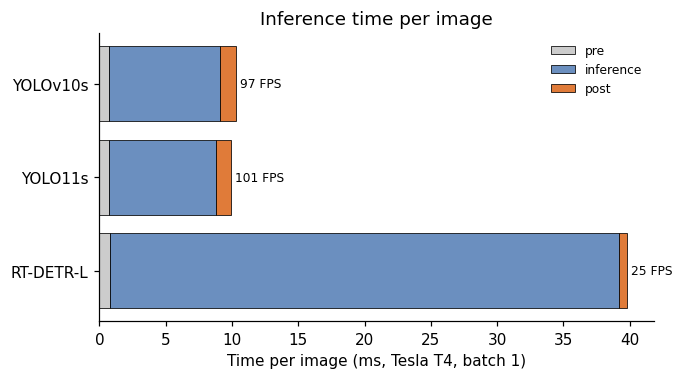

In [11]:
SPEED_TABLE = None
if GPU_READY and HAS_GPU:
    bench_imgs = [str(TEST_IMG / im) for im in TEST_IMAGES[:SPEED_N_IMAGES]]
    gpu = torch.cuda.get_device_name(0); sp = []
    for m in MODEL_ORDER:
        keys = [k for k in WEIGHTS if k[1] == m]
        if not keys: continue
        key = sorted(keys, key=lambda k: (k[0] != "cleaned", k[2]))[0]
        model = load_model(key)
        for p in bench_imgs[:SPEED_WARMUP]:
            model.predict(p, imgsz=IMGSZ, conf=SPEED_CONF, device=DEVICE, verbose=False)
        t = []
        for p in bench_imgs:
            s_ = model.predict(p, imgsz=IMGSZ, conf=SPEED_CONF, device=DEVICE, verbose=False)[0].speed
            t.append([s_["preprocess"], s_["inference"], s_["postprocess"]])
        t = np.array(t); tot = t.sum(1)
        g = runs[runs.model == m]
        sp.append({"model": m, "parameters (M)": g.params_M.mean(), "best.pt (MB)": g.size_MB.mean(),
                   "pre (ms)": t[:, 0].mean(), "inference (ms)": t[:, 1].mean(), "post (ms)": t[:, 2].mean(),
                   "total mean (ms)": tot.mean(), "total P95 (ms)": np.percentile(tot, 95), "FPS": 1000 / tot.mean(),
                   "GPU": gpu, "timed checkpoint": run_label(key)})
        del model; torch.cuda.empty_cache()
    SPEED_TABLE = pd.DataFrame(sp).set_index("model").round(2)
    save_table(SPEED_TABLE, "table_speed_one_session")
    print(f"Batch 1, FP32, {IMGSZ} x {IMGSZ}, {len(bench_imgs)} images after {SPEED_WARMUP} warm-up images\n" + SPEED_TABLE.to_string())

    fig, ax = plt.subplots(figsize=(6.5, 3.4))
    ms = SPEED_TABLE.index; left = np.zeros(len(ms))
    for part, colr in [("pre (ms)", "#cccccc"), ("inference (ms)", "#6b8fbf"), ("post (ms)", "#e07b39")]:
        ax.barh(ms, SPEED_TABLE[part], left=left, color=colr, edgecolor="black", linewidth=0.5, label=part.replace(" (ms)", ""))
        left += SPEED_TABLE[part].values
    for i, m in enumerate(ms):
        ax.text(left[i] + 0.3, i, f"{SPEED_TABLE.at[m, 'FPS']:.0f} FPS", va="center", fontsize=8)
    ax.set_xlabel(f"Time per image (ms, {gpu}, batch 1)"); ax.legend(frameon=False, fontsize=8); ax.set_title("Inference time per image")
    savefig(fig, "speed_one_session")
else:
    print("Skipped: needs a GPU and Ultralytics. Part 4 still gives the times from the training reports.")

#### 10. Challenging conditions
Each model is evaluated on every group. *Difference* = group mAP − full-test mAP of the same model, in percentage points.

Sanity check (cleaned runs): full-test mAP50 here vs report.json, largest difference 0.0000  OK

=== cleaned models on the cleaned test split (mean ± std over seeds) ===
                                    images          mAP50       mAP50-95      AP50 fire     AP50 smoke   recall smoke diff mAP50 vs full (pts)             note
group                    model                                                                                                                                 
Full cleaned test        RT-DETR-L     782  0.501 ± 0.005  0.225 ± 0.004  0.551 ± 0.005  0.450 ± 0.004  0.425 ± 0.001                                          
                         YOLO11s       782  0.470 ± 0.005  0.212 ± 0.003  0.518 ± 0.001  0.423 ± 0.009  0.402 ± 0.002                                          
                         YOLOv10s      782  0.474 ± 0.004  0.214 ± 0.001  0.520 ± 0.003  0.428 ± 0.004  0.405 ± 0.010                                          
Challenging sample (all) RT-DE

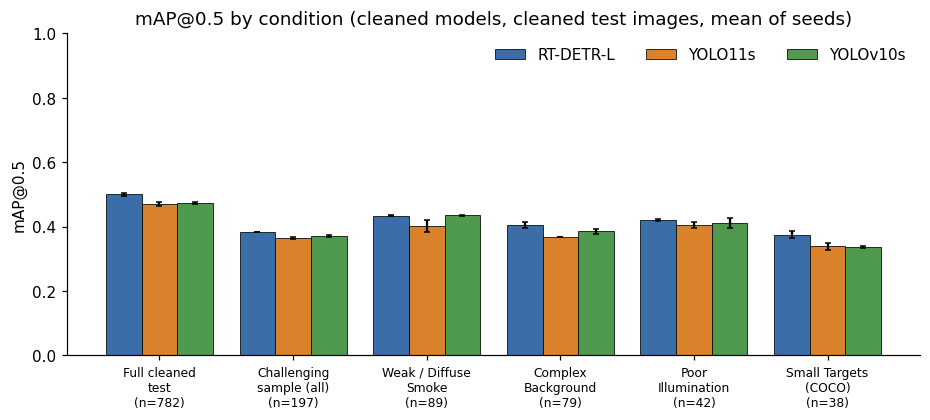

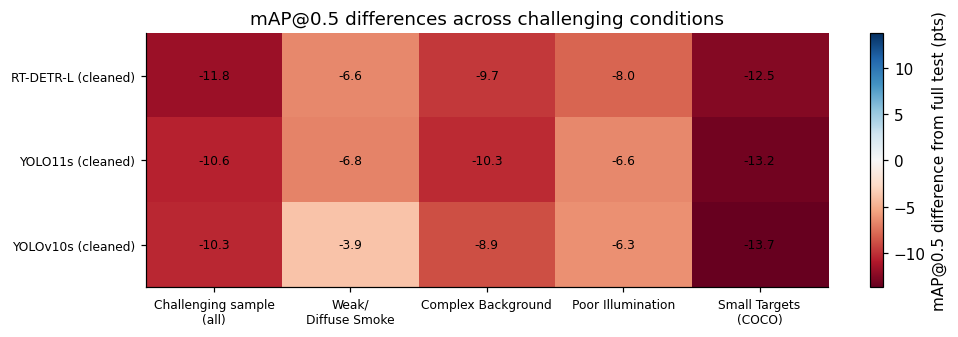

In [12]:
import textwrap
EVAL_CACHE = CACHE / "condition_eval.csv"
done = pd.read_csv(EVAL_CACHE) if EVAL_CACHE.exists() else pd.DataFrame()
done_keys = set(zip(done.dataset, done.model, done.seed.astype(int), done.group)) if len(done) else set()
todo = [k for k in sorted(WEIGHTS, key=lambda k: (DATASETS.index(k[0]), MODEL_ORDER.index(k[1]) if k[1] in MODEL_ORDER else 9, k[2]))
        if k[0] == "cleaned" and any((k[0], k[1], k[2], g) not in done_keys for g in YAMLS)]
if todo and not GPU_READY:
    print("Ultralytics not available: cannot evaluate", len(todo), "runs.")
elif todo:
    for key in todo:
        t0 = time.time(); model = load_model(key); new = []
        for g, y in YAMLS.items():
            if (key[0], key[1], key[2], g) in done_keys: continue
            mt = model.val(data=str(y), split="val", imgsz=IMGSZ, batch=EVAL_BATCH, plots=False, verbose=False,
                           device=DEVICE, project="/content/cond_val", name="v", exist_ok=True)
            row = {"dataset": key[0], "model": key[1], "seed": key[2], "group": g, "images": len(GROUPS[g]),
                   "precision": float(mt.box.mp), "recall": float(mt.box.mr), "mAP50": float(mt.box.map50), "mAP50_95": float(mt.box.map)}
            for j, ci in enumerate(mt.box.ap_class_index):
                p_, r_, a50, a = mt.box.class_result(j); cn = CLASS_NAMES[int(ci)]
                row.update({f"{cn}_AP50": float(a50), f"{cn}_AP50_95": float(a), f"{cn}_recall": float(r_)})
            new.append(row)
        done = pd.concat([done, pd.DataFrame(new)], ignore_index=True); done.to_csv(EVAL_CACHE, index=False)
        done_keys |= {(r["dataset"], r["model"], r["seed"], r["group"]) for r in new}
        print(f"{run_label(key)}: {len(new)} groups in {time.time() - t0:.0f} s")
        del model
        if HAS_GPU: torch.cuda.empty_cache()

COND = done[done.dataset == "cleaned"].copy() if len(done) else done.copy()
if len(COND):
    COND["seed"] = COND.seed.astype(int)
    full = COND[COND.group == "Full cleaned test"].set_index(["dataset", "model", "seed"])
    for c in ("mAP50", "mAP50_95"):
        COND[f"diff {c} (pts)"] = COND.apply(lambda r: 100 * (r[c] - full.at[(r.dataset, r.model, r.seed), c])
                                             if (r.dataset, r.model, r.seed) in full.index else np.nan, axis=1)
    save_table(COND.round(4), "conditions_per_run", index=False)

    chk = full.loc[[k for k in full.index if k[0] == "cleaned" and k in REPORTS]] if len(full) else full
    if len(chk):
        chk = chk.assign(report=[REPORTS[k]["test"]["mAP50"] for k in chk.index])
        diff = (chk.mAP50 - chk.report).abs().max()
        print(f"Sanity check (cleaned runs): full-test mAP50 here vs report.json, largest difference {diff:.4f}"
              + ("  OK" if diff < 0.01 else "  -> CHECK: should be almost identical"))

    g_order = list(GROUPS)
    for ds in [d for d in DATASETS if d in set(COND.dataset)]:
        d = COND[COND.dataset == ds]; rows = []
        for g in g_order:
            for m in model_sort(d.model):
                s = d[(d.group == g) & (d.model == m)]
                if s.empty: continue
                gi = GROUP_INFO.loc[g] if g in GROUP_INFO.index else None
                few = gi is not None and g != "Full cleaned test" and (gi["images"] < MIN_IMAGES)
                n_sm = gi["small smoke boxes"] if g == "Small Targets (COCO)" else gi["smoke boxes"] if gi is not None else 0
                few_smoke = gi is not None and g != "Full cleaned test" and 0 < n_sm < MIN_BOXES
                rows.append({"group": g, "model": m, "images": int(s.images.iloc[0]),
                             "mAP50": pm(s.mAP50), "mAP50-95": pm(s.mAP50_95),
                             "AP50 fire": pm(s.get("fire_AP50", pd.Series(dtype=float))),
                             "AP50 smoke": pm(s.get("smoke_AP50", pd.Series(dtype=float))),
                             "recall smoke": pm(s.get("smoke_recall", pd.Series(dtype=float))),
                             "diff mAP50 vs full (pts)": "" if g == "Full cleaned test" else pm(s["diff mAP50 (pts)"], 1),
                             "note": "; ".join(x for x in ["few images" if few else "", "few smoke boxes" if few_smoke else ""] if x)})
        tab = pd.DataFrame(rows).set_index(["group", "model"])
        save_table(tab, f"table_conditions_{ds}")
        print(f"\n=== {ds} models on the cleaned test split (mean ± std over seeds) ===\n" + tab.to_string())

        groups_here = [g for g in g_order if g in set(d.group)]
        piv = d.groupby(["group", "model"])["mAP50"].mean().unstack("model").reindex(groups_here)
        piv = piv[model_sort(piv.columns)]
        fig, ax = plt.subplots(figsize=(10, 3.8)); x = np.arange(len(piv)); w = 0.8 / max(len(piv.columns), 1)
        for k, m in enumerate(piv.columns):
            sd = d[d.model == m].groupby("group")["mAP50"].std().reindex(piv.index)
            ax.bar(x + (k - (len(piv.columns) - 1) / 2) * w, piv[m].values, w, yerr=np.nan_to_num(sd.values), capsize=2,
                   label=m, color=COLORS.get(m), edgecolor="black", linewidth=0.5)
        ax.set_xticks(x, [textwrap.fill(g, 14) + f"\n(n={len(GROUPS[g])})" for g in piv.index], fontsize=8); ax.set_ylabel("mAP@0.5"); ax.set_ylim(0, 1)
        ax.legend(frameon=False, ncol=3); ax.set_title(f"mAP@0.5 by condition ({ds} models, cleaned test images, mean of seeds)")
        savefig(fig, f"conditions_map50_{ds}")

    hm = COND[COND.group != "Full cleaned test"].groupby(["dataset", "model", "group"])["diff mAP50 (pts)"].mean().unstack("group")
    hm = hm[[g for g in g_order if g in hm.columns]]
    hm = hm.reindex([(ds, m) for ds in DATASETS for m in MODEL_ORDER if (ds, m) in hm.index])
    fig, ax = plt.subplots(figsize=(1.6 * hm.shape[1] + 2, 0.5 * hm.shape[0] + 1.5))
    lim = np.nanmax(np.abs(hm.values)) if np.isfinite(hm.values).any() else 1
    im_ = ax.imshow(hm.values, cmap="RdBu", vmin=-lim, vmax=lim, aspect="auto")
    ax.set_xticks(range(hm.shape[1]), [c.replace(" / ", "/\n").replace(" (", "\n(") for c in hm.columns], fontsize=8)
    ax.set_yticks(range(hm.shape[0]), [f"{m} ({ds})" for ds, m in hm.index], fontsize=8)
    for i in range(hm.shape[0]):
        for j in range(hm.shape[1]):
            v = hm.values[i, j]
            if np.isfinite(v): ax.text(j, i, f"{v:+.1f}", ha="center", va="center", fontsize=8)
    plt.colorbar(im_, ax=ax, label="mAP@0.5 difference from full test (pts)")
    ax.set_title("mAP@0.5 differences across challenging conditions")
    savefig(fig, "conditions_difference_heatmap")

#### 11. Key numbers and files

In [13]:
print("KEY NUMBERS (mean of seeds)")
for ds in DATASETS:
    d = runs[runs.dataset == ds]
    if d.empty: continue
    g = d.groupby("model")[["mAP50", "mAP50_95", "fire_AP50", "smoke_AP50"]].mean()
    best = g.mAP50_95.idxmax()
    print(f"- {ds}: best mAP50-95 = {best} ({g.at[best, 'mAP50_95']:.3f}, mAP50 {g.at[best, 'mAP50']:.3f}); "
          f"smoke AP50 below fire AP50 for {int((g.smoke_AP50 < g.fire_AP50).sum())} of {len(g)} models")
if "COND" in globals() and len(COND):
    c = COND[(COND.dataset == "cleaned") & ~COND.group.isin(["Full cleaned test", "Challenging sample (all)"])].groupby("group")["diff mAP50 (pts)"].mean()
    if len(c): print(f"- cleaned models: hardest condition = {c.idxmin()} ({c.min():+.1f} pts mAP50 vs full test, mean of models)")
if SPEED_TABLE is not None:
    f = SPEED_TABLE["FPS"]; print(f"- fastest: {f.idxmax()} ({f.max():.0f} FPS); slowest: {f.idxmin()} ({f.min():.0f} FPS), batch 1")

print("\nFILES")
for sub in (OUT, TAB, FIG):
    files = sorted(p.name for p in sub.iterdir() if p.is_file())
    print(f"{sub.relative_to(OUT.parent)}/ ({len(files)})"); print("   " + "\n   ".join(files) if files else "   -")

KEY NUMBERS (mean of seeds)
- original: best mAP50-95 = RT-DETR-L (0.327, mAP50 0.591); smoke AP50 below fire AP50 for 3 of 3 models
- cleaned: best mAP50-95 = RT-DETR-L (0.225, mAP50 0.501); smoke AP50 below fire AP50 for 3 of 3 models
- cleaned models: hardest condition = Small Targets (COCO) (-13.1 pts mAP50 vs full test, mean of models)
- fastest: YOLO11s (101 FPS); slowest: RT-DETR-L (25 FPS), batch 1

FILES
results_analysis/ (2)
   all_runs.csv
   categories_final.csv
results_analysis/tables/ (16)
   conditions_per_run.csv
   run_status.csv
   table_benchmark_symmetry.csv
   table_comparison_cleaned.csv
   table_comparison_cleaned_numeric.csv
   table_comparison_original.csv
   table_comparison_original_numeric.csv
   table_condition_groups.csv
   table_conditions_cleaned.csv
   table_convergence.csv
   table_fire_smoke_gap_cleaned.csv
   table_fire_smoke_gap_original.csv
   table_original_vs_cleaned.csv
   table_size_speed_reports_cleaned.csv
   table_size_speed_reports_original